#### AI in Production Management | Spring 2026 | Case Assignment
# Exercise 3: Data Preparation and Exploration for Sorting Line 3

This notebook is the data-preparation and EDA deliverable. It ingests the raw dumps, repairs documented data-quality issues, builds one case-level analytical master table, and extracts operational insight from the unstructured shift logbook.

**Important label convention:** the raw quality CSV uses the inverse of the modeling target: raw zero denotes a passing/good case and raw one denotes a failing/bad case. For all modeling notebooks we convert this to the business-risk convention `Manual_Label = 0` for **BAD** and `Manual_Label = 1` for **GOOD**. The raw value is retained as `Manual_Label_Raw` for auditability.

**Process view from the data flow:**

```text
Truck / charge arrival -> SORTEX case sensor readings -> production timestamp/operator context
                      -> manual quality label by Case_ID -> case-level master table
                      -> shift logbook context for timestamp, operator, and process incidents
```


In [1]:
from pathlib import Path
import os
import re
import sys
import warnings

import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import Markdown, display
from sklearn.metrics import accuracy_score, average_precision_score, confusion_matrix, precision_score, recall_score, roc_auc_score
from sklearn.model_selection import StratifiedKFold, cross_val_predict, train_test_split
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.tree import DecisionTreeClassifier
from sklearn.base import BaseEstimator, TransformerMixin
from sklearn.utils.validation import check_is_fitted
import xgboost as xgb

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid", context="talk")
pd.set_option("display.max_columns", 140)
pd.set_option("display.max_rows", 180)

BASE_DIR = Path.cwd().resolve().parent if Path.cwd().name == "notebooks" else Path.cwd().resolve()
DATA_DIR_150825 = BASE_DIR / "data" / "DataDump_150825"
DATA_DIR_300825 = BASE_DIR / "data" / "DataDump_300825"
OUTPUT_DIR = BASE_DIR / "outputs"
DOTENV_PATH = BASE_DIR / ".env"
OUTPUT_DIR.mkdir(exist_ok=True)


def load_local_env_var(key: str, dotenv_path: Path = DOTENV_PATH):
    existing = os.getenv(key)
    if existing:
        return existing, "environment"
    if not dotenv_path.exists():
        return None, None
    for raw_line in dotenv_path.read_text(errors="ignore").splitlines():
        line = raw_line.strip()
        if not line or line.startswith("#") or "=" not in line:
            continue
        name, value = line.split("=", 1)
        if name.strip() != key:
            continue
        cleaned = value.strip().strip('"').strip("'")
        if cleaned:
            os.environ[key] = cleaned
            return cleaned, f"dotenv:{dotenv_path.name}"
    return None, None

BAD_CLASS = 0
GOOD_CLASS = 1
LABEL_NAMES = {BAD_CLASS: "BAD", GOOD_CLASS: "GOOD"}
RAW_TO_SEMANTIC_LABEL = {0: GOOD_CLASS, 1: BAD_CLASS}
BAD_SHIPPED_COST_CHF = 500
GOOD_WASTED_COST_CHF = 10

def feature_columns(df):
    return sorted([c for c in df.columns if c.startswith("feature_")], key=lambda c: int(c.split("_")[1]))

def standardize_manual_label(df, label_col="Manual_Label", raw_label_col="Manual_Label_Raw"):
    out = df.copy()
    raw = pd.to_numeric(out[label_col], errors="coerce")
    out[raw_label_col] = raw
    out[label_col] = raw.map(RAW_TO_SEMANTIC_LABEL).astype("Int64")
    return out

def add_label_name(df, label_col="Manual_Label"):
    out = df.copy()
    out[f"{label_col}_Name"] = out[label_col].map(LABEL_NAMES)
    return out

def load_master_table():
    df = pd.read_csv(OUTPUT_DIR / "exercise3_master_table_case_level.csv")
    if "Manual_Label" in df.columns:
        df["Manual_Label"] = pd.to_numeric(df["Manual_Label"], errors="coerce").astype("Int64")
    return df

def load_logbook_events():
    return pd.read_csv(OUTPUT_DIR / "logbook_events_structured.csv")

def load_heatwave_table():
    sensor = pd.read_csv(DATA_DIR_300825 / "sensor_data_august_shift.csv")
    quality = pd.read_csv(DATA_DIR_300825 / "quality_labels_august_shift.csv")
    production = pd.read_csv(DATA_DIR_300825 / "production_log_august_shift.csv", parse_dates=["Timestamp"])
    if len(sensor) != len(production):
        raise ValueError("Heatwave sensor and production logs should be row-aligned and equal length.")
    if not sensor["Charge_ID"].reset_index(drop=True).eq(production["Charge_ID"].reset_index(drop=True)).all():
        raise ValueError("Heatwave production rows are not row-aligned with sensor Charge_ID values.")
    table = sensor.merge(quality[["Case_ID", "Manual_Label", "Hash_Validation", "Legacy_Quality_Score"]], on="Case_ID", how="inner")
    if len(table) != len(sensor):
        raise ValueError("Heatwave quality merge changed row count; expected one label per Case_ID.")
    table = pd.concat([table.reset_index(drop=True), production.reset_index(drop=True)[["Timestamp", "Operator_ID"]]], axis=1)
    table = standardize_manual_label(table)
    table["label_available"] = table["Manual_Label"].notna()
    ts = pd.to_datetime(table["Timestamp"], errors="coerce")
    table["production_date"] = ts.dt.date
    table["production_hour"] = ts.dt.hour + ts.dt.minute / 60
    return add_label_name(table)

def _present_columns(df, cols):
    return [c for c in cols if c in df.columns]

def add_urs_rhythm_features(df, reference_df=None, source_features=("feature_2", "feature_4", "feature_5"), window=25):
    out = df.copy()
    signals = _present_columns(out, source_features)
    if not signals:
        raise ValueError("None of the rhythm source features are present.")
    reference = reference_df if reference_df is not None else out
    ref_numeric = reference[signals].apply(pd.to_numeric, errors="coerce")
    medians = ref_numeric.median()
    scales = ref_numeric.std().replace(0, np.nan).fillna(1.0)
    numeric = out[signals].apply(pd.to_numeric, errors="coerce").fillna(medians)
    standardized = (numeric - medians) / scales
    sort_cols = _present_columns(out, ["Timestamp_fixed", "Timestamp", "Charge_ID", "Case_ID"])
    ordered_index = out.sort_values(sort_cols).index if sort_cols else out.index
    ordered = standardized.loc[ordered_index]
    local_change = ordered.diff().abs().mean(axis=1).fillna(0.0)
    rolling_volatility = ordered.rolling(window=window, min_periods=3).std().mean(axis=1).fillna(0.0)
    rhythm = 0.4 * local_change + 0.6 * rolling_volatility
    out["Urs_Local_Signal_Change"] = local_change.reindex(out.index).astype(float)
    out["Urs_Rolling_Signal_Volatility"] = rolling_volatility.reindex(out.index).astype(float)
    out["Urs_Rhythm_Index"] = rhythm.reindex(out.index).astype(float)
    return out

def confusion_counts(y_true, y_pred):
    cm = confusion_matrix(y_true, y_pred, labels=[BAD_CLASS, GOOD_CLASS])
    return {
        "bad_correct": int(cm[0, 0]),
        "bad_shipped": int(cm[0, 1]),
        "good_wasted": int(cm[1, 0]),
        "good_correct": int(cm[1, 1]),
    }

def production_cost_chf(y_true, y_pred):
    counts = confusion_counts(y_true, y_pred)
    return counts["bad_shipped"] * BAD_SHIPPED_COST_CHF + counts["good_wasted"] * GOOD_WASTED_COST_CHF

def classification_summary(y_true, y_pred, model, threshold=None):
    counts = confusion_counts(y_true, y_pred)
    return {
        "model": model,
        "threshold": threshold,
        "rows": len(y_true),
        **counts,
        "bad_shipped_cost_chf": counts["bad_shipped"] * BAD_SHIPPED_COST_CHF,
        "good_wasted_cost_chf": counts["good_wasted"] * GOOD_WASTED_COST_CHF,
        "cost_chf": production_cost_chf(y_true, y_pred),
        "accuracy": accuracy_score(y_true, y_pred),
        "precision_bad": precision_score(y_true, y_pred, pos_label=BAD_CLASS, zero_division=0),
        "recall_bad": recall_score(y_true, y_pred, pos_label=BAD_CLASS, zero_division=0),
        "precision_good": precision_score(y_true, y_pred, pos_label=GOOD_CLASS, zero_division=0),
        "recall_good": recall_score(y_true, y_pred, pos_label=GOOD_CLASS, zero_division=0),
    }

def confusion_frame(y_true, y_pred):
    return pd.DataFrame(
        confusion_matrix(y_true, y_pred, labels=[BAD_CLASS, GOOD_CLASS]),
        index=["Actual BAD (0)", "Actual GOOD (1)"],
        columns=["Pred BAD (0)", "Pred GOOD (1)"],
    )

def predict_from_bad_probability(prob_bad, threshold):
    return pd.Series(np.where(np.asarray(prob_bad) >= threshold, BAD_CLASS, GOOD_CLASS))


## 1. Load Raw Sources

The required data entities are present: case-level sorter measurements, quality labels, production starts, operator master data, sparse machine status, logistics metadata, and three weekly text logbooks. The first audit checks whether these files have the right grain and whether the quality labels can be linked to sensor cases.


In [2]:
sensor = pd.read_csv(DATA_DIR_150825 / "sensor_data_new.csv")
quality_raw = pd.read_csv(DATA_DIR_150825 / "quality_labels.csv")
quality = standardize_manual_label(quality_raw)
production = pd.read_csv(DATA_DIR_150825 / "production_log_large.csv", parse_dates=["Timestamp"])
roster = pd.read_csv(DATA_DIR_150825 / "operator_roster_large.csv")
machine_status = pd.read_csv(DATA_DIR_150825 / "machine_status.csv", parse_dates=["Timestamp"])
logistics = pd.read_csv(DATA_DIR_150825 / "logistics_manifest.csv")
logbook_paths = sorted(DATA_DIR_150825.glob("SHN4_OERLIKON_CW*.txt.txt"))

source_overview = pd.DataFrame([
    {"source": "sensor_data_new.csv", "grain": "one SORTEX case/object", "rows": len(sensor), "columns": sensor.shape[1]},
    {"source": "quality_labels.csv", "grain": "labeled case", "rows": len(quality_raw), "columns": quality_raw.shape[1]},
    {"source": "production_log_large.csv", "grain": "charge start", "rows": len(production), "columns": production.shape[1]},
    {"source": "operator_roster_large.csv", "grain": "operator", "rows": len(roster), "columns": roster.shape[1]},
    {"source": "machine_status.csv", "grain": "status timestamp/parameter", "rows": len(machine_status), "columns": machine_status.shape[1]},
    {"source": "logistics_manifest.csv", "grain": "charge", "rows": len(logistics), "columns": logistics.shape[1]},
    {"source": "shift logbook .txt files", "grain": "free-text event", "rows": len(logbook_paths), "columns": np.nan},
])
label_mapping = add_label_name(quality)[["Manual_Label_Raw", "Manual_Label", "Manual_Label_Name"]].value_counts().reset_index(name="rows")

display(source_overview)
display(label_mapping)


,source,grain,rows,columns
0,sensor_data_new.csv,one SORTEX case/object,2006,35.0
1,quality_labels.csv,labeled case,1404,4.0
2,production_log_large.csv,charge start,74,3.0
3,operator_roster_large.csv,operator,123,3.0
4,machine_status.csv,status timestamp/parameter,16,3.0
5,logistics_manifest.csv,charge,74,6.0
6,shift logbook .txt files,free-text event,3,NaN


,Manual_Label_Raw,Manual_Label,Manual_Label_Name,rows
0,1,0,BAD,722
1,0,1,GOOD,682


## 2. Join Keys and Timestamp Repair

The machine and quality data can be joined directly by `Case_ID`, which is the meaningful primary key for a case/object. `Charge_ID` adds production, operator, and logistics context. The logbook documents a control-PC failure that reset dates to year 2000; those rows are repaired to `2025-08-15` while preserving the original time of day.


In [3]:
assert sensor["Case_ID"].is_unique, "Case_ID must uniquely identify sensor rows."
assert quality_raw["Case_ID"].is_unique, "Case_ID must uniquely identify quality rows."
assert set(quality_raw["Case_ID"]).issubset(set(sensor["Case_ID"])), "Every quality label should have a sensor row."


def repair_year_2000(series, replacement_date="2025-08-15"):
    ts = pd.to_datetime(series, errors="coerce")
    replacement = pd.Timestamp(replacement_date)
    mask = ts.dt.year.eq(2000)
    fixed = ts.copy()
    fixed.loc[mask] = fixed.loc[mask].apply(lambda v: pd.Timestamp.combine(replacement.date(), v.time()) if pd.notna(v) else v)
    return fixed, mask

production["Timestamp_original"] = production["Timestamp"]
production["Timestamp_fixed"], production_broken_mask = repair_year_2000(production["Timestamp"])
machine_status["Timestamp_original"] = machine_status["Timestamp"]
machine_status["Timestamp_fixed"], status_broken_mask = repair_year_2000(machine_status["Timestamp"])

join_audit = pd.DataFrame([
    {"check": "sensor Case_ID unique", "result": sensor["Case_ID"].is_unique},
    {"check": "quality Case_ID unique", "result": quality_raw["Case_ID"].is_unique},
    {"check": "all quality labels link to sensor rows", "result": set(quality_raw["Case_ID"]).issubset(set(sensor["Case_ID"]))},
    {"check": "production rows repaired from year 2000", "result": int(production_broken_mask.sum())},
    {"check": "machine-status rows repaired from year 2000", "result": int(status_broken_mask.sum())},
])
display(join_audit)


,check,result
0,sensor Case_ID unique,True
1,quality Case_ID unique,True
2,all quality labels link to sensor rows,True
3,production rows repaired from year 2000,12
4,machine-status rows repaired from year 2000,4


## 3. Parse Shift Logbooks

The logbook is not just decoration: it explains why some structured data is unreliable. It documents the date-reset incident, PLC session reuse during handover, humidity/condensation problems, belt-speed interventions, vibration issues, and reject-bin events. Those facts shape how the EDA should be interpreted.


In [4]:
ISSUE_KEYWORDS = {
    "it_timekeeping": ["badge", "clock", "timesheet", "bios", "cmos", "year 2000", "server room", "thermal shutdown"],
    "yield_rejects": ["yield", "reject", "rejecting", "reject bin", "ghost-ejecting", "ejector"],
    "belt_or_vibration": ["belt", "vibration", "shaking", "dampener", "slipping", "shaker", "frequency"],
    "humidity_moisture": ["humidity", "moisture", "condensation", "wet", "ice clumps"],
    "sensor_configuration": ["feature", "camera", "calibration", "density sensor", "brix"],
    "maintenance": ["maintenance", "compressor", "oil", "reboot", "hard reset", "tension"],
    "contamination_logistics": ["pallet", "truck", "gate", "contamination", "dirt", "stalk", "stone"],
    "packaging_tape": ["tape", "carton", "box", "cardboard"],
}
HEADER_RE = re.compile(r"^(MONDAY|TUESDAY|WEDNESDAY|THURSDAY|FRIDAY),\s+(\d{2}\.\d{2}\.\d{4})", re.I)
EVENT_RE = re.compile(r"^\[(\d{2}:\d{2}:\d{2})\]\s+\[([^\]]+)\](?:\s+\[([^\]]+)\])?\s*(.*)$")

def tag_issues(text):
    lower = str(text).lower()
    return [tag for tag, words in ISSUE_KEYWORDS.items() if any(word in lower for word in words)]

def parse_logbook(path):
    current_date = None
    events = []
    active = None
    for raw_line in path.read_text(errors="ignore").splitlines():
        line = raw_line.strip()
        if not line:
            continue
        header = HEADER_RE.match(line)
        if header:
            current_date = pd.to_datetime(header.group(2), dayfirst=True).date()
            continue
        event = EVENT_RE.match(line)
        if event and current_date is not None:
            if active is not None:
                events.append(active)
            time_text, actor, event_type, inline = event.groups()
            active = {"source_file": path.name, "date": current_date, "time": time_text, "actor": actor, "event": event_type or actor, "body": inline.strip()}
        elif active is not None and not line.startswith("#") and not set(line) <= {"=", "-"}:
            active["body"] = (active["body"] + " " + line).strip()
    if active is not None:
        events.append(active)
    return events

log_events = pd.DataFrame([event for path in logbook_paths for event in parse_logbook(path)])
log_events["timestamp"] = pd.to_datetime(log_events["date"].astype(str) + " " + log_events["time"], errors="coerce")
log_events["issue_tags"] = log_events["body"].apply(tag_issues)
log_events["issue_tag_count"] = log_events["issue_tags"].str.len()
log_events["week"] = log_events["source_file"].str.extract(r"CW(\d{2})").astype(int)
log_events.to_csv(OUTPUT_DIR / "logbook_events_structured.csv", index=False)

issue_counts = log_events.explode("issue_tags").dropna(subset=["issue_tags"]).groupby(["week", "issue_tags"]).size().reset_index(name="events").sort_values(["week", "events"], ascending=[True, False])
critical_logs = log_events.loc[
    log_events["body"].str.contains("CMOS|year 2000|Feature 31|vibration|belt speed|slipping|yield", case=False, na=False),
    ["timestamp", "actor", "event", "issue_tags", "body"],
].head(14)

display(log_events.head(10))
display(issue_counts.head(20))
display(critical_logs)


,source_file,date,time,actor,event,body,timestamp,issue_tags,issue_tag_count,week
0,SHN4_OERLIKON_CW3125.txt.txt,2025-07-28,05:40:00,4031,MANUAL_LOG,Badge reader at the Sector 4 entrance is blink...,2025-07-28 05:40:00,[it_timekeeping],1,31
1,SHN4_OERLIKON_CW3125.txt.txt,2025-07-28,05:42:00,1691,MANUAL_LOG,Funny how the IT system always breaks when we ...,2025-07-28 05:42:00,[it_timekeeping],1,31
2,SHN4_OERLIKON_CW3125.txt.txt,2025-07-28,05:45:00,4786,SHIFT_START,Starting morning shift. Four days of productio...,2025-07-28 05:45:00,[],0,31
3,SHN4_OERLIKON_CW3125.txt.txt,2025-07-28,05:55:00,1691,MANUAL_LOG,Did anyone watch the Euro final in Basel yeste...,2025-07-28 05:55:00,[],0,31
4,SHN4_OERLIKON_CW3125.txt.txt,2025-07-28,06:02:15,SYSTEM_KERNEL,SYSTEM_KERNEL,BOOT SEQUENCE INITIATED > Unit: Bühler SORTEX ...,2025-07-28 06:02:15,"[belt_or_vibration, sensor_configuration]",2,31
5,SHN4_OERLIKON_CW3125.txt.txt,2025-07-28,06:10:00,8980,MANUAL_LOG,"1691, yes! I was at the public viewing near th...",2025-07-28 06:10:00,[maintenance],1,31
6,SHN4_OERLIKON_CW3125.txt.txt,2025-07-28,06:15:00,4786,MANUAL_LOG,"Hold everything! Before we start the feed, I a...",2025-07-28 06:15:00,[],0,31
7,SHN4_OERLIKON_CW3125.txt.txt,2025-07-28,06:18:00,8980,MANUAL_LOG,Happy work-anniversary to 7290! She brought th...,2025-07-28 06:18:00,[packaging_tape],1,31
8,SHN4_OERLIKON_CW3125.txt.txt,2025-07-28,06:20:00,8461,LOGISTICS_LOG,Charge_ID 88 arriving from Gate A. TransAlp. E...,2025-07-28 06:20:00,[contamination_logistics],1,31
9,SHN4_OERLIKON_CW3125.txt.txt,2025-07-28,06:35:00,4031,MANUAL_LOG,Belt speed set to 1.5 m/s. Everything sounds n...,2025-07-28 06:35:00,[belt_or_vibration],1,31


,week,issue_tags,events
6,31,yield_rejects,28
5,31,sensor_configuration,18
1,31,contamination_logistics,13
0,31,belt_or_vibration,10
3,31,maintenance,7
2,31,it_timekeeping,2
4,31,packaging_tape,2
12,32,packaging_tape,73
14,32,yield_rejects,29
8,32,contamination_logistics,17


,timestamp,actor,event,issue_tags,body
9,2025-07-28 06:35:00,4031,MANUAL_LOG,[belt_or_vibration],Belt speed set to 1.5 m/s. Everything sounds n...
10,2025-07-28 07:05:00,4786,MANUAL_LOG,[yield_rejects],"Line 3 is running, but the yield monitor is fl..."
22,2025-07-28 11:15:00,4786,MANUAL_LOG,"[yield_rejects, maintenance]",Yield is still terrible. Left side rejecting n...
27,2025-07-28 14:00:00,4786,SHIFT_HANDOVER,"[yield_rejects, maintenance]",Handing over to afternoon shift. Line 3 is lim...
35,2025-07-28 17:45:00,1632,MANUAL_LOG,[yield_rejects],Line 3 running. ...And the left side is still ...
54,2025-07-29 06:50:00,1691,MANUAL_LOG,[yield_rejects],Yield is still 83%. The left side is still rej...
71,2025-07-29 14:00:00,4786,SHIFT_HANDOVER,[yield_rejects],Handing over to afternoon shift. Techs are und...
83,2025-07-30 05:55:00,4786,SHIFT_START,[yield_rejects],Morning shift. Yield is 82%. Bühler corporate ...
101,2025-07-30 14:10:00,7662,SHIFT_START,[yield_rejects],Afternoon shift. Yield is 81%. This is brutal.
132,2025-07-31 09:30:00,8980,MANUAL_LOG,[yield_rejects],Yield is 99.1%. The left ejectors are complete...


## 4. LLM-Assisted Logbook Synthesis

The assignment asks us to use the shift logbook to enrich the structured data. This section turns the operator notes into an auditable synthesis. The deterministic table keeps the result reproducible; the LLM call, when a local `GROQ_API_KEY` is available, acts as a qualitative second reader of the same extracted evidence.

The LLM is not allowed to invent new facts. It receives only selected log excerpts and is asked to summarize implications for data quality, process stability, and model deployment.

In [5]:
issue_counts = (
    log_events.explode("issue_tags")
    .dropna(subset=["issue_tags"])
    .groupby(["week", "issue_tags"])
    .size()
    .reset_index(name="events")
    .sort_values(["week", "events"], ascending=[True, False])
)

critical_log_excerpt = log_events.loc[
    log_events["body"].str.contains(
        "CMOS|year 2000|Feature 31|Brix|vibration|belt|humidity|condensation|reject|yield|used Urs",
        case=False,
        regex=True,
        na=False,
    ),
    ["timestamp", "actor", "event", "body", "issue_tags"],
].copy()

llm_evidence_table = pd.DataFrame([
    {
        "theme": "Timestamp integrity",
        "logbook evidence": "Week 33 records a control-PC/BIOS date reset to year 2000.",
        "operational implication": "Repair timestamps before joining production, machine-status, and quality context.",
    },
    {
        "theme": "Operator attribution",
        "logbook evidence": "Week 33 notes PLC sessions were reused during handover.",
        "operational implication": "Treat operator IDs as useful but imperfect context, not clean causal labels.",
    },
    {
        "theme": "Process instability",
        "logbook evidence": "Logs mention vibration, belt-speed interventions, humidity, condensation, and reject-bin events.",
        "operational implication": "Some quality variation is process-driven and should be reflected in engineered features and drift monitoring.",
    },
    {
        "theme": "Feature governance",
        "logbook evidence": "Feature 31/Brix is described as destructive or unsuitable for live sorting.",
        "operational implication": "Exclude feature_31 from deployable PLC rule search even if it is predictive in offline data.",
    },
])

display(issue_counts)
display(critical_log_excerpt.head(20))
display(llm_evidence_table)

prompt_payload = "\n".join([
    "You are reviewing AlpenHarvest Sorting Line 3 shift logbooks for a production ML audit.",
    "Use only the evidence below. Do not introduce facts that are not present in the evidence.",
    "Case roles: Dave is the data/IT intern, Urs is the experienced shift lead/operator, and Beat is the plant manager/business decision maker.",
    "Summarize what the logbook adds beyond the structured CSV data.",
    "Focus on data quality, process stability, operator attribution, and model-deployment risks.",
    "Return concise business-facing bullets for Dave, Urs, and Beat while preserving those roles exactly.",
    "",
    "Deterministic evidence table:",
    llm_evidence_table.to_csv(index=False),
    "",
    "Selected log excerpts:",
    critical_log_excerpt.head(30).to_csv(index=False),
])

llm_summary = None
api_key, api_key_source = load_local_env_var("GROQ_API_KEY")
try:
    from openai import OpenAI
    if api_key:
        client = OpenAI(api_key=api_key, base_url="https://api.groq.com/openai/v1")
        response = client.chat.completions.create(
            model="llama-3.3-70b-versatile",
            messages=[{"role": "user", "content": prompt_payload}],
            temperature=0.2,
            max_tokens=450,
        )
        llm_summary = response.choices[0].message.content.strip()
        llm_status = f"LLM synthesis executed with Groq key loaded from {api_key_source}."
    else:
        llm_summary = "No local GROQ_API_KEY was available, so the deterministic evidence table above is used as the executed synthesis."
        llm_status = "LLM synthesis not executed in this environment."
except Exception as exc:
    llm_summary = f"The external LLM call was unavailable ({type(exc).__name__}: {exc}). The deterministic evidence table above is used as the executed synthesis."
    llm_status = "LLM synthesis fell back to deterministic evidence table."

display(Markdown(f"**{llm_status}**\n\n{llm_summary}"))

,week,issue_tags,events
6,31,yield_rejects,28
5,31,sensor_configuration,18
1,31,contamination_logistics,13
0,31,belt_or_vibration,10
3,31,maintenance,7
2,31,it_timekeeping,2
4,31,packaging_tape,2
12,32,packaging_tape,73
14,32,yield_rejects,29
8,32,contamination_logistics,17


,timestamp,actor,event,body,issue_tags
4,2025-07-28 06:02:15,SYSTEM_KERNEL,SYSTEM_KERNEL,BOOT SEQUENCE INITIATED > Unit: Bühler SORTEX ...,"[belt_or_vibration, sensor_configuration]"
9,2025-07-28 06:35:00,4031,MANUAL_LOG,Belt speed set to 1.5 m/s. Everything sounds n...,[belt_or_vibration]
10,2025-07-28 07:05:00,4786,MANUAL_LOG,"Line 3 is running, but the yield monitor is fl...",[yield_rejects]
11,2025-07-28 07:15:00,1691,MANUAL_LOG,"4786, I'm watching the belt from the catwalk. ...","[yield_rejects, belt_or_vibration]"
14,2025-07-28 07:55:00,4786,MANUAL_LOG,Recalibration didn't work. The SORTEX is still...,"[yield_rejects, belt_or_vibration, sensor_conf..."
15,2025-07-28 08:15:00,3898,QC_LOG,We are wasting prime material here. I just che...,[yield_rejects]
16,2025-07-28 08:40:00,4031,MANUAL_LOG,"The reject bin is already 80% full. Usually, t...",[yield_rejects]
21,2025-07-28 10:30:00,7290,MANUAL_LOG,"Don't worry about the machine, kids. Machines ...","[yield_rejects, maintenance]"
22,2025-07-28 11:15:00,4786,MANUAL_LOG,Yield is still terrible. Left side rejecting n...,"[yield_rejects, maintenance]"
25,2025-07-28 12:45:00,1691,MANUAL_LOG,We have 6 full bins of mixed rejects now. We n...,[yield_rejects]


,theme,logbook evidence,operational implication
0,Timestamp integrity,Week 33 records a control-PC/BIOS date reset t...,"Repair timestamps before joining production, m..."
1,Operator attribution,Week 33 notes PLC sessions were reused during ...,Treat operator IDs as useful but imperfect con...
2,Process instability,"Logs mention vibration, belt-speed interventio...",Some quality variation is process-driven and s...
3,Feature governance,Feature 31/Brix is described as destructive or...,Exclude feature_31 from deployable PLC rule se...


**LLM synthesis executed with Groq key loaded from dotenv:.env.**

Here are the concise business-facing bullets for Dave, Urs, and Beat:

* **Dave (Data/IT Intern)**:
  * Logbook data highlights timestamp integrity issues, requiring repair before joining production data.
  * Operator IDs are useful but imperfect context due to reused PLC sessions during handovers.
  * Feature governance is crucial, as some features (e.g., Feature 31/Brix) are destructive or unsuitable for live sorting.
* **Urs (Experienced Shift Lead/Operator)**:
  * Process instability is evident, with vibration, belt-speed interventions, humidity, condensation, and reject-bin events affecting quality.
  * Operator logs reveal challenges with yield, reject bins, and hand-sorting, emphasizing the need for efficient issue resolution.
  * Maintenance and technical support are essential for resolving issues like the left ejector's rapid-firing problem.
* **Beat (Plant Manager/Business Decision Maker)**:
  * Model-deployment risks are significant, as seen in the SORTEX Optical Sorter's yield issues and reject bin overflows, impacting plant efficiency and profitability.
  * Data quality is critical, with logbook data providing valuable context for production, machine status, and quality issues.
  * Process stability and operator attribution are essential for optimizing production, reducing waste, and improving overall plant performance.

## 5. Sensor Feature Quality Audit

The raw sorter features are not all usable as-is. The notebook keeps the raw features for traceability, but explicitly identifies missing values, constant fields, duplicate copies, and outliers. This matters because downstream classifiers must distinguish process signal from data artefacts.

**Treatment policy:** missing numeric sensor values are retained in the master table and imputed inside modeling pipelines; constant and exact-duplicate fields are flagged so they are not overinterpreted; outliers are retained rather than capped because extreme readings can represent real process instability on Line 3.

In [6]:
features = feature_columns(sensor)
missing = sensor[features].isna().sum().reset_index()
missing.columns = ["feature", "missing_rows"]
missing["missing_pct"] = missing["missing_rows"] / len(sensor)
constant_features = [col for col in features if sensor[col].nunique(dropna=False) <= 1]
duplicate_pairs = []
for i, col_a in enumerate(features):
    for col_b in features[i + 1:]:
        if sensor[col_a].equals(sensor[col_b]):
            duplicate_pairs.append({"kept_feature": col_a, "duplicate_copy": col_b})

outlier_rows = []
for col in features:
    values = pd.to_numeric(sensor[col], errors="coerce").dropna()
    if values.empty or values.nunique() <= 1:
        continue
    q1, q3 = values.quantile([0.25, 0.75])
    iqr = q3 - q1
    if iqr == 0:
        continue
    lower, upper = q1 - 1.5 * iqr, q3 + 1.5 * iqr
    outlier_rows.append({"feature": col, "outlier_rows": int(((values < lower) | (values > upper)).sum()), "outlier_pct": float(((values < lower) | (values > upper)).mean())})
outliers = pd.DataFrame(outlier_rows).sort_values("outlier_pct", ascending=False)

audit_summary = pd.DataFrame([
    {"metric": "raw sensor features", "value": len(features)},
    {"metric": "features with missing values", "value": int((missing["missing_rows"] > 0).sum())},
    {"metric": "constant features", "value": len(constant_features)},
    {"metric": "exact duplicate feature pairs", "value": len(duplicate_pairs)},
])
display(audit_summary)
display(missing.sort_values("missing_rows", ascending=False).head(10))
display(pd.DataFrame({"constant_feature": constant_features}))
display(pd.DataFrame(duplicate_pairs))
display(outliers.head(10))


,metric,value
0,raw sensor features,33
1,features with missing values,3
2,constant features,17
3,exact duplicate feature pairs,137


,feature,missing_rows,missing_pct
31,feature_32,315,0.157029
1,feature_2,276,0.137587
0,feature_1,216,0.107677
30,feature_31,0,0.000000
29,feature_30,0,0.000000
28,feature_29,0,0.000000
27,feature_28,0,0.000000
26,feature_27,0,0.000000
17,feature_18,0,0.000000
24,feature_25,0,0.000000


,constant_feature
0,feature_6
1,feature_8
2,feature_13
3,feature_14
4,feature_15
5,feature_16
6,feature_17
7,feature_18
8,feature_19
9,feature_20


,kept_feature,duplicate_copy
0,feature_6,feature_8
1,feature_6,feature_13
2,feature_6,feature_14
3,feature_6,feature_15
4,feature_6,feature_16
5,feature_6,feature_17
6,feature_6,feature_18
7,feature_6,feature_19
8,feature_6,feature_20
9,feature_6,feature_21


,feature,outlier_rows,outlier_pct
7,feature_27,692,0.344965
6,feature_9,103,0.051346
11,feature_32,77,0.045535
4,feature_5,85,0.042373
8,feature_29,75,0.037388
9,feature_30,75,0.037388
12,feature_33,67,0.033400
5,feature_7,62,0.030907
1,feature_2,53,0.030636
2,feature_3,59,0.029412


## 6. Build the Master Table

The analytical grain is one SORTEX case/object. `Manual_Label_Raw` preserves the original quality CSV value; `Manual_Label` is the semantic modeling target (`0 = BAD`, `1 = GOOD`). `Charge_ID` brings in production, operator, logistics, and sparse machine-status context.


In [7]:
status_wide = machine_status.pivot_table(index="Timestamp_fixed", columns="Parameter", values="Value", aggfunc="last").reset_index().rename_axis(None, axis=1)
master = (
    sensor.merge(quality[["Case_ID", "Manual_Label_Raw", "Manual_Label", "Hash_Validation", "Legacy_Quality_Score"]], on="Case_ID", how="left")
    .merge(production[["Charge_ID", "Timestamp_fixed", "Timestamp_original", "Operator_ID"]], on="Charge_ID", how="left")
    .merge(roster, on="Operator_ID", how="left")
    .merge(logistics, on="Charge_ID", how="left")
    .merge(status_wide, on="Timestamp_fixed", how="left")
)
master["label_available"] = master["Manual_Label"].notna()
master = add_label_name(master)
master["production_date"] = pd.to_datetime(master["Timestamp_fixed"], errors="coerce").dt.date
master["production_hour"] = pd.to_datetime(master["Timestamp_fixed"], errors="coerce").dt.hour + pd.to_datetime(master["Timestamp_fixed"], errors="coerce").dt.minute / 60
master["shift_guess"] = pd.cut(master["production_hour"], bins=[-0.01, 5.75, 14.0, 23.99], labels=["Night/Pre-start", "Morning", "Late"])
master["operator_attribution_note"] = np.where(master["Timestamp_fixed"].dt.date.astype(str).eq("2025-08-13"), "Logbook warns PLC sessions were reused during handover", "Observed production log id")

master_path = OUTPUT_DIR / "exercise3_master_table_case_level.csv"
master.to_csv(master_path, index=False)

label_summary = master.groupby(["label_available", "Manual_Label", "Manual_Label_Name"], dropna=False).size().reset_index(name="rows")
display(Markdown(f"Saved semantic master table to `{master_path.relative_to(BASE_DIR)}` with **{len(master):,} rows**."))
display(label_summary)
display(master.head())


Saved semantic master table to `outputs/exercise3_master_table_case_level.csv` with **2,006 rows**.

,label_available,Manual_Label,Manual_Label_Name,rows
0,False,<NA>,NaN,602
1,True,0,BAD,722
2,True,1,GOOD,682


,Case_ID,Charge_ID,feature_1,feature_2,feature_3,feature_4,feature_5,feature_6,feature_7,feature_8,feature_9,feature_10,feature_11,feature_12,feature_13,feature_14,feature_15,feature_16,feature_17,feature_18,feature_19,feature_20,feature_21,feature_22,feature_23,feature_24,feature_25,feature_26,feature_27,feature_28,feature_29,feature_30,feature_31,feature_32,feature_33,Manual_Label_Raw,Manual_Label,Hash_Validation,Legacy_Quality_Score,Timestamp_fixed,Timestamp_original,Operator_ID,Name,Role,Logistics_Provider,Truck_Plate,Arrival_Gate,Pallet_Type,RFID_Tag,Belt_Speed_m_s,Humidity_Pct,label_available,Manual_Label_Name,production_date,production_hour,shift_guess,operator_attribution_note
0,23,0,61.0,1092.0,30,175,34,0,7,0,30,0,5,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,89,0,10,10,132,-137.0,22,NaN,<NA>,NaN,NaN,2025-08-11 11:31:30,2025-08-11 11:31:30,4786,Urs Mueller,Shift Lead,SpeedyLogistics,ZH-30392,Gate B,Euro-Pool,A8021EB0318D33B4,1.5,45.0,False,NaN,2025-08-11,11.516667,Morning,Observed production log id
1,32,0,41.0,778.0,21,105,21,0,6,0,17,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,-48,0,4,4,112,-20.0,23,0.0,1,7a551341,0.1996,2025-08-11 11:31:30,2025-08-11 11:31:30,4786,Urs Mueller,Shift Lead,SpeedyLogistics,ZH-30392,Gate B,Euro-Pool,A8021EB0318D33B4,1.5,45.0,True,GOOD,2025-08-11,11.516667,Morning,Observed production log id
2,52,0,79.0,NaN,30,210,33,0,19,0,56,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,78,0,7,7,167,-91.0,43,0.0,1,3c407aa4,0.4581,2025-08-11 11:31:30,2025-08-11 11:31:30,4786,Urs Mueller,Shift Lead,SpeedyLogistics,ZH-30392,Gate B,Euro-Pool,A8021EB0318D33B4,1.5,45.0,True,GOOD,2025-08-11,11.516667,Morning,Observed production log id
3,60,0,49.0,1119.0,34,160,28,0,10,0,47,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,92,0,10,10,162,NaN,17,NaN,<NA>,NaN,NaN,2025-08-11 11:31:30,2025-08-11 11:31:30,4786,Urs Mueller,Shift Lead,SpeedyLogistics,ZH-30392,Gate B,Euro-Pool,A8021EB0318D33B4,1.5,45.0,False,NaN,2025-08-11,11.516667,Morning,Observed production log id
4,69,0,91.0,NaN,39,210,35,0,13,0,33,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,3,0,3,3,154,-28.0,74,NaN,<NA>,NaN,NaN,2025-08-11 11:31:30,2025-08-11 11:31:30,4786,Urs Mueller,Shift Lead,SpeedyLogistics,ZH-30392,Gate B,Euro-Pool,A8021EB0318D33B4,1.5,45.0,False,NaN,2025-08-11,11.516667,Morning,Observed production log id


## 7. EDA: Production Rhythm and Label Coverage

Bad rate is calculated explicitly as the share of semantic `Manual_Label == 0`. This avoids the common mistake of treating the numeric label mean as a defect rate after labels have been standardized.


,production_date,cases,bad_rate,good_rate
0,2025-08-11,638,0.120690,0.879310
1,2025-08-12,97,0.752577,0.247423
2,2025-08-13,136,0.867647,0.132353
3,2025-08-14,286,0.818182,0.181818
4,2025-08-15,247,0.890688,0.109312


,Charge_ID,cases,bad_rate,good_rate
32,408,1,1.0,0.0
26,312,10,1.0,0.0
28,403,1,1.0,0.0
17,303,5,1.0,0.0
29,404,1,1.0,0.0
30,405,1,1.0,0.0
31,407,1,1.0,0.0
33,409,1,1.0,0.0
37,504,15,1.0,0.0
38,505,10,1.0,0.0


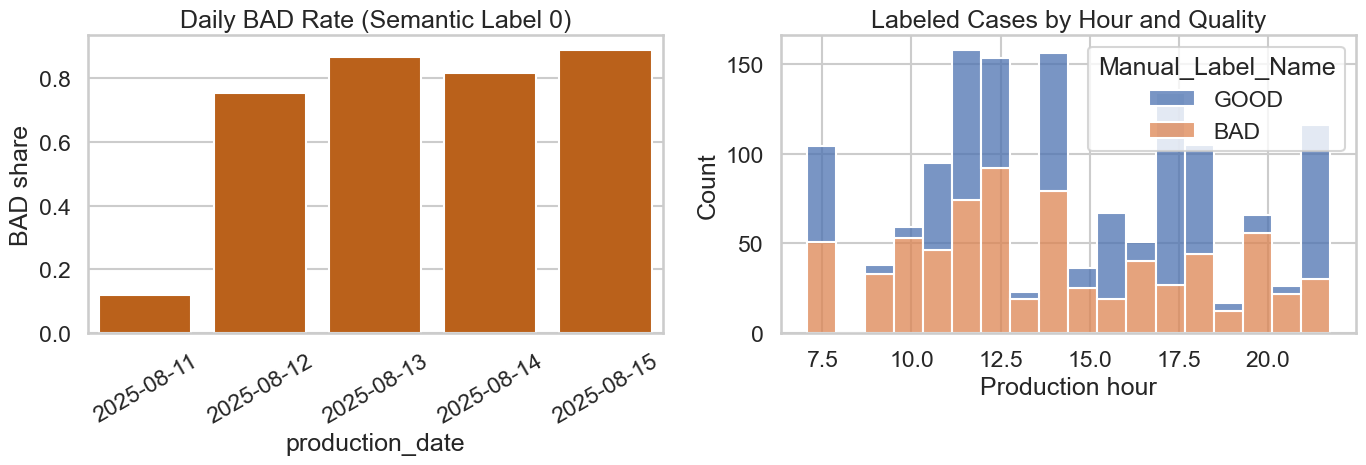

In [8]:
labeled = master.loc[master["label_available"]].copy()
labeled["Manual_Label"] = labeled["Manual_Label"].astype(int)
labeled["is_bad"] = labeled["Manual_Label"].eq(BAD_CLASS)
labeled["is_good"] = labeled["Manual_Label"].eq(GOOD_CLASS)

daily = labeled.groupby("production_date").agg(cases=("Case_ID", "count"), bad_rate=("is_bad", "mean"), good_rate=("is_good", "mean")).reset_index()
charge_quality = labeled.groupby("Charge_ID").agg(cases=("Case_ID", "count"), bad_rate=("is_bad", "mean"), good_rate=("is_good", "mean")).reset_index()

display(daily)
display(charge_quality.sort_values("bad_rate", ascending=False).head(10))

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
sns.barplot(data=daily, x="production_date", y="bad_rate", ax=axes[0], color="#d55e00")
axes[0].set_title("Daily BAD Rate (Semantic Label 0)")
axes[0].set_ylabel("BAD share")
axes[0].tick_params(axis="x", rotation=30)
sns.histplot(data=labeled, x="production_hour", hue="Manual_Label_Name", multiple="stack", bins=18, ax=axes[1])
axes[1].set_title("Labeled Cases by Hour and Quality")
axes[1].set_xlabel("Production hour")
plt.tight_layout()
plt.show()


## 8. Feature Interdependencies and Operational Context

The strongest univariate feature relationships are measured against the BAD indicator. Positive correlation means the feature tends to rise when cases are BAD; negative correlation means it tends to rise when cases are GOOD. These are screening relationships, not causal proof.


,feature,corr_with_bad,mean_when_BAD,mean_when_GOOD,abs_corr
13,feature_31,-0.710751,74.534626,136.589443,0.710751
0,feature_1,-0.633371,20.478939,61.840198,0.633371
14,feature_32,0.628954,14.903179,-43.606000,0.628954
3,feature_4,-0.620148,60.554017,160.851906,0.620148
15,feature_33,-0.620100,5.500000,39.693548,0.620100
1,feature_2,-0.580872,300.527378,921.521318,0.580872
5,feature_7,-0.555980,2.789474,11.288856,0.555980
2,feature_3,-0.555969,15.941828,27.206745,0.555969
4,feature_5,-0.548442,14.853186,30.755132,0.548442
6,feature_9,-0.511439,12.333795,36.136364,0.511439


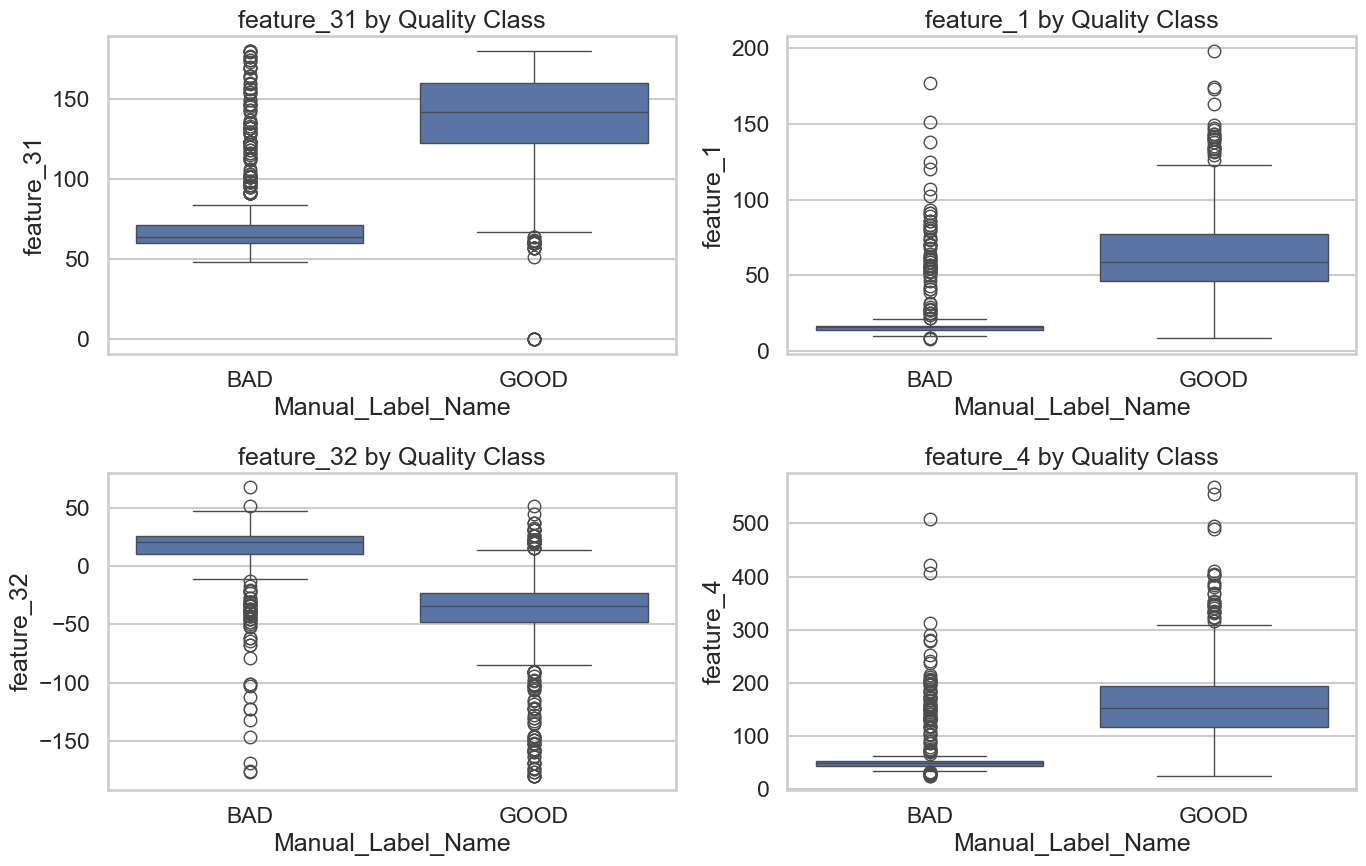

,Logistics_Provider,cases,bad_rate,context,Pallet_Type,Arrival_Gate,Name
5,NaN,737,0.538670,Arrival_Gate,NaN,Gate B,NaN
4,NaN,667,0.487256,Arrival_Gate,NaN,Gate A,NaN
0,SpeedyLogistics,795,0.548428,Logistics_Provider,NaN,NaN,NaN
1,TransAlp,609,0.469622,Logistics_Provider,NaN,NaN,NaN
7,NaN,1,1.000000,Name,NaN,NaN,Katya Novak
8,NaN,1186,0.540472,Name,NaN,NaN,Urs Mueller
6,NaN,217,0.368664,Name,NaN,NaN,Dave Liebknecht
3,NaN,550,0.598182,Pallet_Type,Plastic,NaN,NaN
2,NaN,854,0.460187,Pallet_Type,Euro-Pool,NaN,NaN


In [9]:
feature_stats = []
for col in features:
    values = pd.to_numeric(labeled[col], errors="coerce")
    if values.nunique(dropna=True) <= 1:
        continue
    corr = values.corr(labeled["is_bad"].astype(float))
    grouped = labeled.groupby("Manual_Label_Name")[col].mean(numeric_only=True).to_dict()
    feature_stats.append({"feature": col, "corr_with_bad": corr, "mean_when_BAD": grouped.get("BAD", np.nan), "mean_when_GOOD": grouped.get("GOOD", np.nan), "abs_corr": abs(corr) if pd.notna(corr) else np.nan})
feature_stats = pd.DataFrame(feature_stats).sort_values("abs_corr", ascending=False)
top_features = feature_stats.head(8)["feature"].tolist()
display(feature_stats.head(12))

fig, axes = plt.subplots(2, 2, figsize=(14, 9))
for ax, col in zip(axes.ravel(), top_features[:4]):
    sns.boxplot(data=labeled, x="Manual_Label_Name", y=col, order=["BAD", "GOOD"], ax=ax)
    ax.set_title(f"{col} by Quality Class")
plt.tight_layout()
plt.show()

context_rates = []
for col in ["Logistics_Provider", "Pallet_Type", "Arrival_Gate", "Name"]:
    if col in labeled.columns:
        context_rates.append(labeled.groupby(col).agg(cases=("Case_ID", "count"), bad_rate=("is_bad", "mean")).reset_index().assign(context=col))
context_rates = pd.concat(context_rates, ignore_index=True)
display(context_rates.sort_values(["context", "bad_rate"], ascending=[True, False]).head(20))


## 9. EDA Synthesis for the Business Case

The data is usable for modeling, but it is not plug-and-play. The business implication is that any production AI must include data-governance controls: timestamp validation, label lineage, operator-session caveats, and monitoring for physical process changes documented by the shop floor.


In [10]:
findings = pd.DataFrame([
    {"finding": "Primary key", "business implication": "Case_ID makes a defensible bridge between SORTEX measurements and quality outcomes; Charge_ID adds production context."},
    {"finding": "Label lineage", "business implication": "Raw labels are preserved, but modeling uses 0=BAD and 1=GOOD so cost-sensitive mistakes are unambiguous."},
    {"finding": "Timestamp consistency", "business implication": f"{int(production_broken_mask.sum())} production rows and {int(status_broken_mask.sum())} machine-status rows required repair; deployment needs automatic date sanity checks."},
    {"finding": "Missing values", "business implication": "Only feature_1, feature_2, and feature_32 contain missing sensor values; model pipelines must impute them consistently."},
    {"finding": "Outlier treatment", "business implication": "Outliers are flagged but retained because extreme sorter readings can be real process instability rather than data errors."},
    {"finding": "Sensor quality", "business implication": f"{len(constant_features)} constant features and {len(duplicate_pairs)} exact duplicate pair should not be overinterpreted as process signals."},
    {"finding": "LLM-assisted logbook synthesis", "business implication": "The logbook synthesis turns operator notes into deployment rules: repair timestamps, treat operator IDs cautiously, monitor vibration/humidity, and exclude destructive/offline Feature 31 from PLC deployment."},
    {"finding": "Logbook value", "business implication": "The logbook explains the root causes behind structured anomalies: PLC session reuse, Brix misuse, humidity, belt speed, vibration, and reject-bin events."},
])
display(findings)
display(Markdown("\n".join(f"- **{row['finding']}:** {row['business implication']}" for row in findings.to_dict("records"))))


,finding,business implication
0,Primary key,Case_ID makes a defensible bridge between SORT...
1,Label lineage,"Raw labels are preserved, but modeling uses 0=..."
2,Timestamp consistency,12 production rows and 4 machine-status rows r...
3,Missing values,"Only feature_1, feature_2, and feature_32 cont..."
4,Outlier treatment,Outliers are flagged but retained because extr...
5,Sensor quality,17 constant features and 137 exact duplicate p...
6,LLM-assisted logbook synthesis,The logbook synthesis turns operator notes int...
7,Logbook value,The logbook explains the root causes behind st...


- **Primary key:** Case_ID makes a defensible bridge between SORTEX measurements and quality outcomes; Charge_ID adds production context.
- **Label lineage:** Raw labels are preserved, but modeling uses 0=BAD and 1=GOOD so cost-sensitive mistakes are unambiguous.
- **Timestamp consistency:** 12 production rows and 4 machine-status rows required repair; deployment needs automatic date sanity checks.
- **Missing values:** Only feature_1, feature_2, and feature_32 contain missing sensor values; model pipelines must impute them consistently.
- **Outlier treatment:** Outliers are flagged but retained because extreme sorter readings can be real process instability rather than data errors.
- **Sensor quality:** 17 constant features and 137 exact duplicate pair should not be overinterpreted as process signals.
- **LLM-assisted logbook synthesis:** The logbook synthesis turns operator notes into deployment rules: repair timestamps, treat operator IDs cautiously, monitor vibration/humidity, and exclude destructive/offline Feature 31 from PLC deployment.
- **Logbook value:** The logbook explains the root causes behind structured anomalies: PLC session reuse, Brix misuse, humidity, belt speed, vibration, and reject-bin events.